In [31]:
## -- System dependencies --
import sys, os, gc
import torch

## -- Device-Agnostic (GPU/CPU) --
def get_system_info():
    if torch.cuda.is_available():
        return f"GPU: {torch.cuda.get_device_name(0)}"
    else:
        return f"CPU: {os.cpu_count()}"

get_system_info()

'GPU: Tesla T4'

In [32]:
%matplotlib inline
%config InlineBackend.figure_format = 'svg'

In [33]:
# %load_ext cuml.accel
# %load_ext cudf.pandas

In [34]:
try:
    from colorama import Fore, Style
except:
    !pip install -q colorama
    from colorama import Fore, Style

In [35]:
## -- Data Manipulation --
import numpy as np, pandas as pd, random

## -- Visualization --
from IPython.display import display, Image
import matplotlib.pyplot as plt
import seaborn as sns

## -- Functional Tools --
import gc
import shutil
import itertools
from tqdm.auto import tqdm
from time import time, sleep

## -- Machine Learning --
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
from torch.optim.lr_scheduler import SequentialLR, LinearLR, CosineAnnealingLR

from sklearn.model_selection import KFold, train_test_split
from sklearn.preprocessing import QuantileTransformer, LabelEncoder, TargetEncoder as skTE

from sklearn.calibration import CalibrationDisplay
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.metrics import roc_auc_score, ConfusionMatrixDisplay, RocCurveDisplay

import warnings
warnings.simplefilter('ignore')
warnings.filterwarnings('ignore')

## -- Global Settings --
# sklearn.set_config(transform_output='pandas')

# pd.options.mode.copy_on_write = True
pd.set_option('display.max_columns', 100)
# sns.set_style("whitegrid")
# plt.style.use('ggplot')

def seed_everything(seed: int):
    print(f"✓ Seed everything at {seed}")
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

seed_everything(42)

✓ Seed everything at 42


In [36]:
TEAL, GOLD, CORAL, BLUE, DARK, CRIM, MUTED, INK, PAPER = '#168c91','#e8b44f','#dc705a',\
                                                         'dodgerblue','#0B4F7A','crimson',\
                                                         '#627D98','#102A43','#faf9f5'
plt.rcParams.update({
    'figure.facecolor': PAPER,
    'axes.facecolor': PAPER,
    'savefig.facecolor': PAPER,
    'font.family': 'DejaVu Sans',
    'font.size': 9,
    'axes.titlesize': 12,
    'axes.titleweight': 'semibold',
    'axes.labelcolor': INK,
    'text.color': INK,
    'xtick.color': DARK,
    'ytick.color': DARK,
    'axes.edgecolor': MUTED,
    'axes.spines.top': False,
    'axes.spines.right': False,
    'axes.grid': True,
    'grid.alpha': 0.25,
    'grid.color': MUTED,
    'patch.edgecolor': DARK,
    # 'patch.force_edgecolor': True,
    # 'patch.linewidth': 1.5,
    # 'figure.dpi':110,
    # 'savefig.dpi':160,
})
# CMAP = LinearSegmentedColormap.from_list('atlas', ['#f0f5ef','#a9d6ca',TEAL,INK])
sns.set_palette([TEAL, GOLD, CORAL, BLUE, MUTED, CRIM, DARK, INK, PAPER])

## -- Set Global Seed --
CFG = {
    'FOLDS':  5,
    'SEED':   42,
    'GREEN':  '\033[32m',
    'YELLOW': '\033[33m',
    'RESET':  '\033[0m'
}

print(f"CLASSIC {CFG['GREEN']} GREEN {CFG['RESET']} {CFG['YELLOW']} YELLOW {CFG['RESET']}")

CLASSIC  GREEN   YELLOW 


In [37]:
## -- ⚠️ IMPORTANT: SELECT PLATFORM ⚠️ --
PLATFORM = "colab" # -> 'colab' 'kaggle'

if PLATFORM == "kaggle":
    PATH = "/kaggle/input/competitions/playground-series-s6e10/"
    submit = pd.read_csv(PATH+"sample_submission.csv")
    train = pd.read_csv(PATH+"train.csv")
    test = pd.read_csv(PATH+"test.csv")

    ORIG_PATH = "/kaggle/input/datasets/arseniyshutko/binary-aviation-satisfaction-129k/"
    orig = pd.read_csv(ORIG_PATH+"data.csv")
elif PLATFORM == "colab":
    from google.colab import drive
    drive.mount("/content/drive")

    PATH   = "/content/drive/MyDrive/-- shared_notebooks --/Ps6e10 | Airline Satisfaction/_airline_data/"
    submit = pd.read_csv(PATH+"sample_submission.csv")
    train  = pd.read_csv(PATH+"train.csv")
    test   = pd.read_csv(PATH+"test.csv")
    orig   = pd.read_csv(PATH+"data.csv")

## =================================================================================

TARGET, ID = 'satisfaction', 'id'

train[TARGET] = train[TARGET].map({True: 1, False: 0})
orig[TARGET] = orig[TARGET].map({True: 1, False: 0})

obj = train.select_dtypes(include=["object", "category"]).columns.tolist()

cat_cols  = [c for c in obj if c not in [TARGET, ID]]
num_cols  = [c for c in train.columns if c not in cat_cols+[TARGET, ID]]
base_cols = [c for c in train.columns if c not in [TARGET, ID]]

service_cols = [
    'Inflight wifi service', 'Departure/Arrival time convenient', 'Ease of Online booking',
    'Gate location', 'Food and drink', 'Online boarding', 'Seat comfort',
    'Inflight entertainment', 'On-board service', 'Leg room service',
    'Baggage handling', 'Checkin service', 'Cleanliness'
]

train = train[base_cols+[TARGET]]
orig  = orig[base_cols+[TARGET]]
test  = test[base_cols]

print(f"Frame type: {type(train)}\n")

for (name, df) in {"Train": train, "Test": test, 'Orig': orig}.items(): #
    print(f"{name} shape: {df.shape}")

print(f"Total Numerical: {len(num_cols)}")
print(f"Total Categorical: {len(cat_cols)}")
print(f"Total base features: {len(base_cols)}")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Frame type: <class 'pandas.core.frame.DataFrame'>

Train shape: (699635, 22)
Test shape: (299844, 21)
Orig shape: (129880, 22)
Total Numerical: 17
Total Categorical: 4
Total base features: 21


In [38]:
train[num_cols] = train[num_cols].fillna(0)
test[num_cols] = test[num_cols].fillna(0)
orig[num_cols] = orig[num_cols].fillna(0)

train.isna().sum()

,0
Age,0
Flight Distance,0
Inflight wifi service,0
Departure/Arrival time convenient,0
Ease of Online booking,0
Gate location,0
Food and drink,0
Online boarding,0
Seat comfort,0
Inflight entertainment,0


In [39]:
# train.head()

In [40]:
# train.describe().T

In [41]:
train_len = len(train)
test_len  = len(test)

n_unique = train.nunique().sort_values()
n_unique

,0
satisfaction,2
Type of Travel,2
Customer Type,2
Gender,2
Class,3
Baggage handling,5
Gate location,6
Departure/Arrival time convenient,6
Leg room service,6
Checkin service,6


In [42]:
from sklearn.base import BaseEstimator, TransformerMixin ## ===== Target/Category Mean ENCODERS =====

class customTE(BaseEstimator, TransformerMixin):
    """
    Target Encoder that supports multiple aggregation functions,
    internal cross-validation for leakage prevention, and smoothing.

    Parameters
    ----------
    cols_to_encode : list of str
        List of column names to be target encoded.

    aggs : list of str, default=['mean']
        List of aggregation functions to apply. Any function accepted by
        pandas' `.agg()` method is supported, such as:
        'mean', 'std', 'var', 'min', 'max', 'skew', 'nunique',
        'count', 'sum', 'median'.
        Smoothing is applied only to the 'mean' aggregation.

    cv : int, default=5
        Number of folds for cross-validation in fit_transform.

    smooth : float or 'auto', default='auto'
        The smoothing parameter `m`. A larger value puts more weight on the
        global mean. If 'auto', an empirical Bayes estimate is used.

    drop_original : bool, default=False
        If True, the original columns to be encoded are dropped.
    """
    def __init__(self, cols_to_encode, aggs=['mean'], cv=5, smooth='auto', drop_original=False):
        self.cols_to_encode = cols_to_encode
        self.aggs = aggs
        self.cv = cv
        self.smooth = smooth
        self.drop_original = drop_original
        self.mappings_ = {}
        self.global_stats_ = {}

    def fit(self, X, y):
        """
        Learn mappings from the entire dataset.
        These mappings are used for the transform method on validation/test data.
        """
        temp_df = X.copy()
        temp_df['target'] = y

        # Learn global statistics for each aggregation
        for agg_func in self.aggs:
            self.global_stats_[agg_func] = y.agg(agg_func)

        # Learn category-specific mappings
        for col in self.cols_to_encode:
            self.mappings_[col] = {}
            for agg_func in self.aggs:
                mapping = temp_df.groupby(col)['target'].agg(agg_func)
                self.mappings_[col][agg_func] = mapping

        return self

    def transform(self, X):
        """
        Apply learned mappings to the data.
        Unseen categories are filled with global statistics.
        """
        X_transformed = X.copy()
        for col in self.cols_to_encode:
            for agg_func in self.aggs:
                new_col_name = f'TE_{col}_{agg_func}'
                map_series = self.mappings_[col][agg_func]
                X_transformed[new_col_name] = X[col].map(map_series)
                X_transformed[new_col_name].fillna(self.global_stats_[agg_func], inplace=True)

        if self.drop_original:
            X_transformed.drop(columns=self.cols_to_encode, inplace=True)

        return X_transformed

    def fit_transform(self, X, y):
        """
        Fit and transform the data using internal cross-validation to prevent leakage.
        """
        # First, fit on the entire dataset to get global mappings for transform method
        self.fit(X, y)

        # Initialize an empty DataFrame to store encoded features
        encoded_features = pd.DataFrame(index=X.index)

        kf = KFold(n_splits=self.cv, shuffle=True, random_state=42)

        for train_idx, val_idx in kf.split(X, y):
            X_train, y_train = X.iloc[train_idx], y.iloc[train_idx]
            X_val = X.iloc[val_idx]

            temp_df_train = X_train.copy()
            temp_df_train['target'] = y_train

            for col in self.cols_to_encode:
                # --- Calculate mappings only on the training part of the fold ---
                for agg_func in self.aggs:
                    new_col_name = f'TE_{col}_{agg_func}'

                    # Calculate global stat for this fold
                    fold_global_stat = y_train.agg(agg_func)

                    # Calculate category stats for this fold
                    mapping = temp_df_train.groupby(col)['target'].agg(agg_func)

                    # --- Apply smoothing only for 'mean' aggregation ---
                    if agg_func == 'mean':
                        counts = temp_df_train.groupby(col)['target'].count()

                        m = self.smooth
                        if self.smooth == 'auto':
                            # Empirical Bayes smoothing
                            variance_between = mapping.var()
                            avg_variance_within = temp_df_train.groupby(col)['target'].var().mean()
                            if variance_between > 0:
                                m = avg_variance_within / variance_between
                            else:
                                m = 0  # No smoothing if no variance between groups

                        # Apply smoothing formula
                        smoothed_mapping = (counts * mapping + m * fold_global_stat) / (counts + m)
                        encoded_values = X_val[col].map(smoothed_mapping)
                    else:
                        encoded_values = X_val[col].map(mapping)

                    # Store encoded values for the validation fold
                    encoded_features.loc[X_val.index, new_col_name] = encoded_values.fillna(fold_global_stat)

        # Merge with original DataFrame
        X_transformed = X.copy()
        for col in encoded_features.columns:
            X_transformed[col] = encoded_features[col]

        if self.drop_original:
            X_transformed.drop(columns=self.cols_to_encode, inplace=True)

        return X_transformed


class CategoryMeanTransformer(BaseEstimator, TransformerMixin):
    def __init__(self, cat_cols=None):
        self.cat_cols = cat_cols
        self.mappings_ = {}
    def fit(self, X, y):
        X = X.copy()
        if self.cat_cols is None:
            self.cat_cols = X.select_dtypes(include=['category']).columns.tolist()
        self.mappings_ = {}
        for col in self.cat_cols:
            df_temp = pd.DataFrame({col: X[col], 'y': y})
            group_means = df_temp.groupby(col, dropna=False)['y'].mean()
            sorted_categories = group_means.sort_values().index
            self.mappings_[col] = {cat: i for i, cat in enumerate(sorted_categories)}

        return self

    def transform(self, X, y=None):
        X = X.copy()
        for col, mapping in self.mappings_.items():
            if col in X.columns:
                X[col] = X[col].map(mapping)

        return X

In [43]:
def original_TE(
    orig: pd.DataFrame,
    df: pd.DataFrame,
    features: list=None,
    target: str=None,
    aggs: list=None,
    fill_nan: bool=False,
):

    if features is None or len(features) == 0:
        return df.copy()

    if aggs is None or len(aggs) == 0:
        return df.copy()

    X_df = df.copy()

    orig_cols = []
    maps = {}

    valid_features = [col for col in features if col in orig.columns]

    for col in tqdm(valid_features, desc="original_augmenting"):
        for agg_ in aggs:
            agg_key = agg_.lower()
            new_col = f"oTE_{col}_{agg_key}"

            map_key = (col, agg_key)
            if map_key not in maps:
                try:
                    if agg_key == 'mean':
                        map_df = (orig.groupby(col)[target].mean().reset_index(name=new_col))
                    elif agg_key == 'median':
                        map_df = (orig.groupby(col)[target].median().reset_index(name=new_col))
                    elif agg_key == 'count':
                        map_df = (orig.groupby(col).size().reset_index(name=new_col)) #.astype('int32')
                    elif agg_key == 'nunique':
                        map_df = (orig.groupby(col)[target].nunique().reset_index(name=new_col)) #.astype('int32')
                    elif agg_key == 'std':
                        map_df = (orig.groupby(col)[target].std().reset_index(name=new_col))
                    elif agg_key == 'skew':
                        map_df = (orig.groupby(col)[target].skew().reset_index(name=new_col))
                    elif agg_key == 'max':
                        map_df = (orig.groupby(col)[target].max().reset_index(name=new_col))
                    elif agg_key == 'min':
                        map_df = (orig.groupby(col)[target].min().reset_index(name=new_col))
                    else:
                        continue
                except Exception as e:
                    print(f"Warning: failed to create map for col={col}, agg={agg_}: {e}")
                    continue

                maps[map_key] = map_df

            map_df = maps.get(map_key)
            if map_df is None:
                continue

            # Merge maps into each split
            X_df = X_df.merge(map_df.astype('float32'), on=col, how='left')

            orig_cols.append(new_col)

    global_mean   = orig[target].mean()
    global_median = orig[target].median()

    def fill_conditionally(df):
        for c in orig_cols:
            if '_mean' in c or '_max' in c or '_min' in c:
                df[c] = df[c].fillna(global_mean)
            elif '_median' in c:
                df[c] = df[c].fillna(global_median)
            else:
                df[c] = df[c].fillna(0)
        return df

    if fill_nan:
        X_df = fill_conditionally(X_df)

    return X_df, orig_cols

print("-- Data augment function ready! --")

-- Data augment function ready! --


## FEATURE ENGINEERING

In [44]:
# ## -- DIGITS EXTRACTION --
# FEATURES = [c for c in train.columns if c not in [ID, TARGET]]
# combined = pd.concat([train, test, orig])

# digit_cols = []
# cols_select = ["Flight Distance"]

# for col in cols_select:
#     scaled = (combined[col].fillna(0) * (10**4)).astype('int64')
#     for k in range(-4, 4):
#         dig_col = f"{col}_digit{k}"
#         combined[dig_col] = (scaled // 10**(k+4) % 10).astype('int32').astype('category')
#         # combined[dig_col] = (combined[col].fillna(0) // (10**k) % 10).astype('int32').astype('category')
#         digit_cols.append(dig_col)

# train = combined.iloc[:train_len]
# test = combined.iloc[train_len:train_len+test_len].drop(columns=[TARGET])
# orig = combined.iloc[-len(orig):]

# # Check nunique, and find which ones are < 2
# unique_counts = train[digit_cols].nunique()
# drop_cols = unique_counts[unique_counts < 2].index.tolist()

# # update digit cols for keep
# digit_cols = [i for i in set(digit_cols) if i not in set(drop_cols)]

# # drop constant features
# train = train.drop(columns=drop_cols)
# test  = test.drop(columns=drop_cols)
# orig  = orig.drop(columns=drop_cols)

# del combined
# print(f"Total digit features: {len(digit_cols)}\n")

# train[digit_cols].nunique()

In [45]:
# ## -- Cyclic encoding --

# for df in [train, test]:
#     for p in [8, 12, 24]:
#         df[f"sleep_hours_sin_{p}"] = np.sin(2 * np.pi * df["sleep_hours"] / p).astype("float32")
#         df[f"sleep_hours_cos_{p}"] = np.cos(2 * np.pi * df["sleep_hours"] / p).astype("float32")

In [46]:
## -- Factorize cat_cols -- ⚠️

FEATURES = [c for c in train.columns if c not in [ID, TARGET]]
print("Total features before operation:", len(FEATURES))

combined = pd.concat([train, test, orig])
## ------------------------------------------------------------------------
for c in tqdm(cat_cols, desc="factorize_cats"):
    combined[c] = pd.factorize(combined[c], sort=True)[0].astype('int32')
## ------------------------------------------------------------------------
GROUPERS = []
for col in service_cols:
    g_col = f"{col}_FD_GROUPBY".replace(" ", "")
    combined[g_col+'_mean'] = combined.groupby(['Flight Distance'])[col].transform('mean')
    # combined[g_col+'_std'] = combined.groupby(['Flight Distance'])[col].transform('std')
    GROUPERS.append(g_col)
FEATURES = list(set(FEATURES + GROUPERS))
## ------------------------------------------------------------------------
# for c in tqdm(cat_cols, desc="categorize_cats"):
#     combined[c] = combined[c].astype("category")
## ------------------------------------------------------------------------
train = combined.iloc[:train_len]
test  = combined.iloc[train_len:train_len+test_len].drop(columns=[TARGET])
orig  = combined.iloc[train_len+test_len:]

del combined
print("Total features after operation:", len(FEATURES))

Total features before operation: 21


factorize_cats:   0%|          | 0/4 [00:00<?, ?it/s]

Total features after operation: 34


In [47]:
## -- NUMERIC TO CATEGORY for TargetEncoding -- ⚠️

FEATURES = [c for c in train.columns if c not in [ID, TARGET]]
print("Features before operation:", len(FEATURES))

combined = pd.concat([train, test])
## ------------------------------------------------------------
# # -- Duplicate Nums as Cats --
nums_to_cats = []
select_nc = ["Flight Distance"]
for c in tqdm(select_nc, desc="nums_to_cats"):
    n_cat = f"{c}_cat_"
    combined[n_cat] = pd.factorize(combined[c], sort=True)[0].astype('int32')
    # combined[n] = combined[n].astype('category')
    nums_to_cats.append(n_cat)
FEATURES = list(set(FEATURES + nums_to_cats))
## ------------------------------------------------------------
train = combined.iloc[:train_len]
test  = combined.iloc[train_len:train_len+test_len].drop(columns=[TARGET])
# orig  = combined.iloc[train_len+test_len:]

del combined
print("Features after operation:", len(FEATURES))

Features before operation: 34


nums_to_cats:   0%|          | 0/1 [00:00<?, ?it/s]

Features after operation: 35


In [48]:
train.head()

,Age,Flight Distance,Inflight wifi service,Departure/Arrival time convenient,Ease of Online booking,Gate location,Food and drink,Online boarding,Seat comfort,Inflight entertainment,On-board service,Leg room service,Baggage handling,Checkin service,Cleanliness,Departure Delay in Minutes,Arrival Delay in Minutes,Gender,Customer Type,Type of Travel,Class,satisfaction,Inflightwifiservice_FD_GROUPBY_mean,Departure/Arrivaltimeconvenient_FD_GROUPBY_mean,EaseofOnlinebooking_FD_GROUPBY_mean,Gatelocation_FD_GROUPBY_mean,Foodanddrink_FD_GROUPBY_mean,Onlineboarding_FD_GROUPBY_mean,Seatcomfort_FD_GROUPBY_mean,Inflightentertainment_FD_GROUPBY_mean,On-boardservice_FD_GROUPBY_mean,Legroomservice_FD_GROUPBY_mean,Baggagehandling_FD_GROUPBY_mean,Checkinservice_FD_GROUPBY_mean,Cleanliness_FD_GROUPBY_mean,Flight Distance_cat_
0,36,694,4,4,4,3,1,4,1,1,3,4,4,3,1,0,0.0,0,0,1,1,0.0,2.821429,3.704670,2.649725,2.951923,3.440934,3.142857,3.505495,3.458791,3.565934,3.166209,3.831044,3.563187,3.510989,481
1,56,651,5,5,5,5,5,4,4,5,5,5,5,4,3,0,0.0,1,0,0,0,1.0,2.735716,2.770772,2.787389,3.085591,3.052811,3.054405,3.223310,3.147507,3.153654,3.228318,3.540633,3.078306,3.099476,448
2,31,1371,3,4,2,5,3,3,3,3,4,3,4,5,3,0,0.0,0,0,1,1,0.0,2.865449,3.637874,2.850498,2.973422,3.267442,3.335548,3.588040,3.360465,3.674419,3.456811,3.845515,3.737542,3.440199,1028
3,10,1616,3,5,3,3,3,3,3,3,4,5,3,4,3,0,0.0,1,0,1,1,0.0,2.737403,3.344961,2.868217,2.957364,3.414729,3.484496,3.777132,3.698643,3.795543,3.724806,3.968992,3.644380,3.586240,1237
4,23,481,3,4,3,4,5,3,5,5,5,4,5,3,5,5,0.0,0,1,0,1,0.0,2.768374,2.918708,2.824053,3.189310,3.241648,3.074610,3.358575,3.335189,3.109131,3.236080,3.467706,2.889755,3.250557,305


In [49]:
# ## -- Frequency encoding -- ⚠️
# freq_cols = []

# combined = pd.concat([train, test], ignore_index=True)
# select_freq = ["Flight Distance"]
# #, "Age", "Arrival Delay in Minutes", "Departure Delay in Minutes"] + service_cols

# print("\nCreating frequencies (Safe Global Mapping)...")
# for col in select_freq:
#     n = f"_freq_{col}"
#     print(f"⧗ {n}", end="")

#     # Calculate frequencies using ONLY train
#     freq_map = train[col].value_counts(dropna=False, normalize=False).to_dict()

#     # Map the training-derived frequencies across all datasets safely
#     train[n] = train[col].map(freq_map).fillna(0).astype("float32")
#     test[n]  = test[col].map(freq_map).fillna(0).astype("float32")
#     # orig[n] = orig[col].map(freq_map).fillna(0).astype("float32")

#     freq_cols.append(n)
#     print()

# # num_cols = list(set(num_cols + freq_cols))
# # FEATURES = list(set(FEATURES + freq_cols))

# del combined
# print(f"\n *** Total frequency features: {len(freq_cols)}")

In [50]:
# ## FLOOR/BIN FEATURES -- ⚠️
# floor_cols = []

# combined = pd.concat([train, test, orig])

# for f in tqdm([500], desc='Floor features (bins)'):
#     # print(f, end='-> ')
#     for c in ['Flight Distance']:
#         f_name = f"{c}_//_{f}"
#         print(f" ⧗ {f_name}", end='... ')
#         # combined[f_name] = (combined[c].fillna(0) // f).astype('int32')
#         combined[f_name] = (combined[c].fillna(0) // f).astype('int32').astype('category')
#         floor_cols.append(f_name)
#         print()

# # for f in tqdm([10], desc='Floor features (bins)'):
# #     # print(f, end='-> ')
# #     for c in ['Departure Delay in Minutes', 'Arrival Delay in Minutes']:
# #         f_name = f"{c}_//_{f}"
# #         print(f" ⧗ {f_name}", end='... ')
# #         combined[f_name] = (combined[c] // f).astype('int32')
# #         floor_cols.append(f_name)
# #         print()

# # for f in tqdm([5], desc='Floor features (bins)'):
# #     # print(f, end='-> ')
# #     for c in ['Age']:
# #         f_name = f"{c}_//_{f}"
# #         print(f" ⧗ {f_name}", end='... ')
# #         combined[f_name] = (combined[c] // f).astype('int32')
# #         floor_cols.append(f_name)
# #         print()

# # combined['age5_X_dist500'] = combined['Age_//_5'] * combined['Flight Distance_//_500']

# # FEATURES = list(set(FEATURES + floor_cols))

# train = combined.iloc[:train_len]
# test  = combined.iloc[train_len:train_len+test_len].drop(columns=[TARGET])
# orig  = combined.iloc[train_len+test_len:]

# del combined
# print(f"\n*** Total floor features: {len(floor_cols)}")

# print(train[floor_cols].nunique(dropna=False))

In [53]:
train.nunique()[-20:]

,0
Arrival Delay in Minutes,168
Gender,2
Customer Type,2
Type of Travel,2
Class,3
satisfaction,2
Inflightwifiservice_FD_GROUPBY_mean,2481
Departure/Arrivaltimeconvenient_FD_GROUPBY_mean,2517
EaseofOnlinebooking_FD_GROUPBY_mean,2466
Gatelocation_FD_GROUPBY_mean,2425


In [54]:
USE_FULL_TRAIN = True

x_sample, x_sample2 = train_test_split(
    train,
    train_size=100_000,
    stratify=train[TARGET],
    random_state=42
)

train_X = train.copy() if USE_FULL_TRAIN else x_sample.reset_index(drop=True)
print(train_X.shape, type(train_X))

_ = [c for c in train_X.columns if c not in [ID, TARGET]]
FEATURES = list(set(_))

print(f"Train shape {train_X.shape}")
# train_X.head()

(699635, 36) <class 'pandas.core.frame.DataFrame'>
Train shape (699635, 36)


In [55]:
## -- Handle optional original table aggregations --
USE_ORIGINAL = True

import_cols  = ['Flight Distance', 'Age'] + cat_cols + service_cols

if USE_ORIGINAL:
    aggs_ = ["mean"]  # "mean", "count", "std", "skew", "nunique",
    feats = FEATURES.copy()
    x_train, orig_cols = original_TE(
        orig, train_X, target=TARGET, features = import_cols,
        aggs=aggs_, fill_nan=True
    )
    x_test, _ = original_TE(
        orig, test, target=TARGET, features = import_cols,
        aggs=aggs_, fill_nan=True
    )
    feats.extend(orig_cols)
    X = x_train[feats]
    X_test = x_test[feats]
    y = train_X[TARGET].astype("int32")
else:
    X = train_X[FEATURES]
    X_test = test[FEATURES]
    y = train_X[TARGET].astype("int32")

print(X.shape, type(X))
# X.head()

original_augmenting:   0%|          | 0/19 [00:00<?, ?it/s]

original_augmenting:   0%|          | 0/19 [00:00<?, ?it/s]

(699635, 54) <class 'pandas.core.frame.DataFrame'>


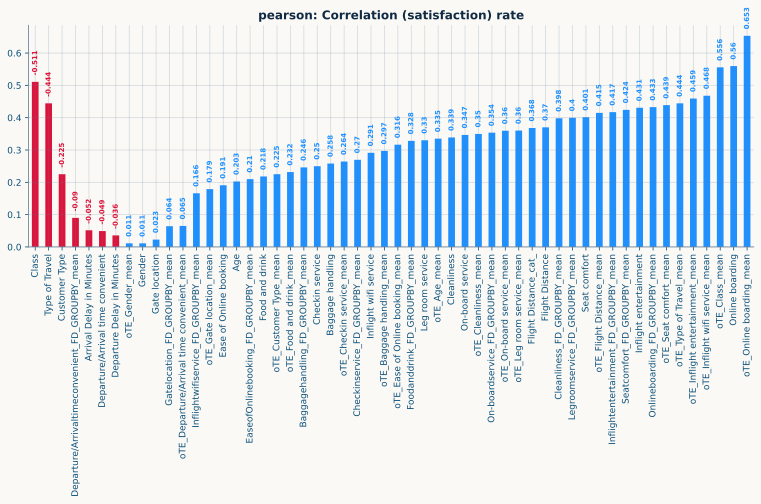

In [56]:
corr_type = ['pearson', 'spearman'][0]

plt.figure(figsize=(13, 4))
corr_df = X.corrwith(train_X[TARGET], method=corr_type).sort_values()
corr_df.abs().plot(kind='bar', color=[CRIM if c < 0 else BLUE for c in corr_df.values])
for i, v in enumerate(corr_df.values):
    plt.text(
        i, np.abs(v) + 0.02, np.round(v, 3),
        size=7, weight='semibold', color=CRIM if v < 0 else BLUE,
        va='bottom', ha='center', rotation=90,
    )

plt.title(f"{corr_type}: Correlation ({TARGET}) rate")
plt.show()

In [57]:
## -- Reduce data memory --
def reduce_memory(df):
    old_size = df.memory_usage(deep=True).sum() / (1024*1024)
    for c in tqdm(df.columns, desc='Reducing memory...'):
        if df[c].dtype == np.int64:
            ## -- Downcast Integer type ---
            if df[c].min() > np.iinfo(np.int32).min and df[c].max() < np.iinfo(np.int32).max:
                df[c] = df[c].astype(np.int32)
                # if df[c].min() > np.iinfo(np.int16).min and df[c].max() < np.iinfo(np.int16).max:
                #     df[c] = df[c].astype(np.int16)
                #     if df[c].min() > np.iinfo(np.int8).min and df[c].max() < np.iinfo(np.int8).max:
                #         df[c] = df[c].astype(np.int8)
        elif df[c].dtype == np.float64:
            ## -- Downcast Float type -----
            if df[c].min() > np.finfo(np.float32).min and df[c].max() < np.finfo(np.float32).max:
                df[c] = df[c].astype(np.float32)
                # if df[c].min() > np.finfo(np.float16).min and df[c].max() < np.finfo(np.float16).max:
                #     df[c] = df[c].astype(np.float16)

    new_size = df.memory_usage(deep=True).sum() / (1024*1024)
    print(f"Size before process: {old_size:.1f} MB\nSize after process : {new_size:.1f}MB\n")

    return df

X = reduce_memory(X)
X_test = reduce_memory(X_test)
# orig = reduce_memory(orig)

print(f"Data memory reduced!")
gc.collect()

Reducing memory...:   0%|          | 0/54 [00:00<?, ?it/s]

Size before process: 226.9 MB
Size after process : 144.1MB



Reducing memory...:   0%|          | 0/54 [00:00<?, ?it/s]

Size before process: 97.2 MB
Size after process : 61.8MB

Data memory reduced!


14152

In [58]:
# ## -- Get label/counts for categories --
# full_data = pd.concat([X, X_test])

# cat_dims  = []
# for c in cat_cols:
#     le = LabelEncoder().fit(full_data[c].astype(str))
#     X[c] = le.transform(X[c].astype(str))
#     X_test[c] = le.transform(X_test[c].astype(str))
#     cat_dims.append(len(le.classes_))

# del full_data

# for k, v in zip(cat_cols, cat_dims):
#     print(f"{k:>15s}: {v}")

# ML TRAINING

In [59]:
# - PyTorch Dataset & FT-Transformer Architecture
class TabularDataset(Dataset):
    def __init__(self, x_cat, x_num, y=None):
        self.x_cat = torch.tensor(x_cat, dtype=torch.long)
        self.x_num = torch.tensor(x_num, dtype=torch.float32)
        self.y = torch.tensor(y, dtype=torch.float32) if y is not None else None

    def __len__(self):
        return len(self.x_num)

    def __getitem__(self, idx):
        if self.y is not None:
            return self.x_cat[idx], self.x_num[idx], self.y[idx]
        return self.x_cat[idx], self.x_num[idx]

class FTTransformer(nn.Module):
    def __init__(self, cat_dims, num_features, d_token=32, n_blocks=3, n_heads=4, ff_dropout=0.1):
        super().__init__()
        self.cat_dims = cat_dims
        self.num_features = num_features

        # Tokenize Categoricals
        self.cat_embeddings = nn.ModuleList([
            nn.Embedding(num_classes, d_token) for num_classes in cat_dims
        ])

        # Tokenize Numericals (each numerical feature gets multiplied by a learned weight vector to become d_token dim)
        self.num_embeddings = nn.Parameter(torch.randn(num_features, d_token))
        self.num_biases = nn.Parameter(torch.randn(num_features, d_token))

        # [CLS] Token (like in BERT, used for final classification)
        self.cls_token = nn.Parameter(torch.randn(1, 1, d_token))

        # Standard Transformer Encoder Blocks
        encoder_layer = nn.TransformerEncoderLayer(
            d_model=d_token,
            nhead=n_heads,
            dim_feedforward=d_token * 2,
            dropout=ff_dropout,
            batch_first=True
        )
        self.transformer = nn.TransformerEncoder(encoder_layer, num_layers=n_blocks)

        # Final prediction head
        self.head = nn.Sequential(
            nn.LayerNorm(d_token),
            nn.Linear(d_token, d_token // 2),
            nn.ReLU(),
            nn.Linear(d_token // 2, 1)
        )

    def forward(self, x_cat, x_num):
        batch_size = x_num.size(0)

        # 1. Process Categoricals
        cat_embs = []
        for i, emb in enumerate(self.cat_embeddings):
            cat_embs.append(emb(x_cat[:, i]).unsqueeze(1)) # Shape: (batch_size, 1, d_token)

        # 2. Process Numericals
        # x_num is (batch_size, num_features)
        # self.num_embeddings is (num_features, d_token)
        num_embs = x_num.unsqueeze(-1) * self.num_embeddings.unsqueeze(0) + self.num_biases.unsqueeze(0)

        # 3. Combine
        if len(cat_embs) > 0:
            cat_embs = torch.cat(cat_embs, dim=1)
            x = torch.cat([cat_embs, num_embs], dim=1) # Shape: (batch_size, num_cat + num_num, d_token)
        else:
            x = num_embs

        # 4. Add CLS Token
        cls_tokens = self.cls_token.expand(batch_size, -1, -1)
        x = torch.cat([cls_tokens, x], dim=1) # Shape: (batch_size, 1 + num_cat + num_num, d_token)

        # 5. Transformer Pass
        x = self.transformer(x)

        # 6. Extract CLS token output and classify
        cls_out = x[:, 0, :]
        return self.head(cls_out).squeeze(1)

print("PyTorch Dataset & FT-Transformer Architecture")

PyTorch Dataset & FT-Transformer Architecture


In [68]:
te_cols = nums_to_cats

class CFG:
    TE    = True if len(te_cols) > 0 else False
    FOLDS = 5
    SEED  = 42
    BATCH = 2048//8 if torch.cuda.is_available() else 128
    EPOCH = 20

FOLDS = 5
skf = StratifiedKFold(n_splits=FOLDS, shuffle=True, random_state=42)

all_cats = list(set(cat_cols))

model_name = "torch_FTTse"
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"\n🚀 Training {model_name} with {FOLDS}-Folds | Device: {device}\n")

oof_preds  = np.zeros(len(X))
test_preds = np.zeros(len(X_test))

fold_scores = []
best_iterations = []
feat_importances = []

t0 = time()
for fold, (tr_idx, val_idx) in enumerate(skf.split(X, y), 1):
    X_tr, X_val = X.iloc[tr_idx].copy(), X.iloc[val_idx].copy()
    y_tr, y_val = y.iloc[tr_idx].values, y.iloc[val_idx].values
    X_tst = X_test.copy()

    print("="*15)
    print(f"### Fold {fold}/{FOLDS}")
    print("="*15)

    # Target encoding
    if CFG.TE:
        smooth = 'auto'
        print(f"⚡️ scikit_TE (smooth={smooth}) | features ({len(te_cols)})")
        TE = skTE(target_type='binary', cv=5, smooth=smooth, random_state=42)
        tr_enc = TE.fit_transform(X_tr[te_cols], y_tr)
        va_enc = TE.transform(X_val[te_cols])
        ts_enc = TE.transform(X_tst[te_cols])

        te_names = [f"TE{smooth}_{col}" for col in te_cols]
        X_tr[te_names]  = tr_enc
        X_val[te_names] = va_enc
        X_tst[te_names] = ts_enc

        combos_to_drop = te_cols

        X_tr  = X_tr.drop(columns=combos_to_drop)
        X_val = X_val.drop(columns=combos_to_drop)
        X_tst = X_tst.drop(columns=combos_to_drop)

    # ------------------------------------------------------------------------------
    ## -- Get category label/dimensions --
    cat_dims  = []
    full_data = pd.concat([X, X_val, X_test])
    for c in all_cats:
        le = LabelEncoder().fit(full_data[c].astype(str))
        X_tr[c] = le.transform(X_tr[c].astype(str))
        X_val[c] = le.transform(X_val[c].astype(str))
        X_tst[c] = le.transform(X_tst[c].astype(str))
        cat_dims.append(len(le.classes_))
    print("Cats dims:", dict(zip(all_cats, cat_dims)))
    # ------------------------------------------------------------------------------
    X_tr_cat   = X_tr[all_cats]
    X_val_cat  = X_val[all_cats]
    X_test_cat = X_tst[all_cats]

    get_nums   = X_tr.columns.difference(all_cats, sort=False).tolist()
    X_tr_num   = X_tr[get_nums]
    X_val_num  = X_val[get_nums]
    X_test_num = X_tst[get_nums]

    qt = QuantileTransformer(output_distribution='normal', random_state=42)
    X_tr_num    = qt.fit_transform(X_tr_num)
    X_val_num   = qt.transform(X_val_num)
    X_test_num  = qt.transform(X_test_num)

    train_dataset = TabularDataset(np.asarray(X_tr_cat), np.asarray(X_tr_num), y_tr)
    val_dataset   = TabularDataset(np.asarray(X_val_cat), np.asarray(X_val_num), y_val)
    test_dataset  = TabularDataset(np.asarray(X_test_cat), np.asarray(X_test_num))

    train_loader = DataLoader(train_dataset, batch_size=CFG.BATCH, shuffle=True)
    val_loader   = DataLoader(val_dataset, batch_size=CFG.BATCH, shuffle=False)
    test_loader  = DataLoader(test_dataset, batch_size=CFG.BATCH, shuffle=False)
    # ------------------------------------------------------------------------------
    if fold == 1: print(f"batch={CFG.BATCH}, train={X_tr.shape}, valid={X_val.shape}")

    params = {
        'lr':     1e-3,
        'token':  64, # 32, 64, 96... (⬆+32)
        'heads':  8,  # 4, 8
        'blocks': 3,
        'drop':   0.1,
        'wd':     0.0,
    }

    model = FTTransformer(
        cat_dims=cat_dims,
        num_features=X_tr_num.shape[1],
        d_token=params['token'],
        n_blocks=params['blocks'],
        n_heads=params['heads'],
        ff_dropout=params['drop'],
    ).to(device)

    criterion = nn.BCEWithLogitsLoss()
    optimizer = optim.AdamW(model.parameters(), lr=params['lr'], weight_decay=params['wd'])

    warmup_epochs = 2
    scheduler1 = LinearLR(optimizer, start_factor=0.1, total_iters=warmup_epochs)
    scheduler2 = CosineAnnealingLR(optimizer, T_max=CFG.EPOCH - warmup_epochs)
    scheduler  = SequentialLR(optimizer, schedulers=[scheduler1, scheduler2], milestones=[warmup_epochs])
    # ------------------------------------------------------------------------
    best_val_auc = 0
    best_epoch   = 0

    for epoch in range(CFG.EPOCH):
        model.train()
        train_loss = 0
        for b_cat, b_num, b_y in train_loader:
            b_cat, b_num, b_y = b_cat.to(device), b_num.to(device), b_y.to(device)

            optimizer.zero_grad()
            logits = model(b_cat, b_num)
            loss = criterion(logits, b_y)
            loss.backward()
            optimizer.step()
            train_loss += loss.item()

        scheduler.step()

        model.eval()
        val_preds = []
        val_targets = []
        with torch.no_grad():
            for b_cat, b_num, b_y in val_loader:
                b_cat, b_num = b_cat.to(device), b_num.to(device)
                logits = model(b_cat, b_num)
                val_preds.extend(torch.sigmoid(logits).cpu().numpy())
                val_targets.extend(b_y.cpu().numpy())

        val_auc = roc_auc_score(val_targets, val_preds)
        print(f"Epoch {epoch+1}/{CFG.EPOCH} AUC: {val_auc:.6f}")

        if val_auc > best_val_auc:
            best_epoch = epoch+1
            best_val_auc = val_auc
            torch.save(model.state_dict(), f"ft_fold_{fold}.pth")
            oof_preds[val_idx] = val_preds

    fold_score = best_val_auc
    fold_scores.append(fold_score)
    best_iterations.append(best_epoch)
    # ------------------------------------------------------------------------
    model.load_state_dict(torch.load(f"ft_fold_{fold}.pth", weights_only=True))
    model.eval()
    fold_test_preds = []
    with torch.no_grad():
        for b_cat, b_num in test_loader:
            b_cat, b_num = b_cat.to(device), b_num.to(device)
            logits = model(b_cat, b_num)
            fold_test_preds.extend(torch.sigmoid(logits).cpu().numpy())

    test_preds += np.array(fold_test_preds)

    print("-"*30)
    print(f"-> Fold {fold} AUC: {Fore.YELLOW}{Style.BRIGHT}{fold_score:.6f}{Style.RESET_ALL} Iter: #{best_epoch}\n")
    torch.cuda.empty_cache()

test_preds /= FOLDS

model_name = model_name + f"({X_tr.shape[1]})"
features_used = X_tr.columns

## -- CV results --
fold_results = {}

print(f"\n{'='*50}")
print(f"{FOLDS}-FOLD CV: {model_name} | {X_tr.shape}")
print(f"{'='*50}")
for i, (s, t) in enumerate(zip(fold_scores, best_iterations), 1):
    print(f" • Fold {i} AUC: {s:.6f} @ tree {t}")
    fold_results[f'fold_{i}'] = s

## -- Final out-of-fold score --
oof_auc = np.round(roc_auc_score(y, oof_preds), 6)
avg_auc = np.round(np.mean(fold_scores), 6)
std_auc = np.round(np.std(fold_scores), 6)

print("-"*50)
print(f"OOF score: {Fore.BLUE}{Style.BRIGHT}{oof_auc}{Style.RESET_ALL}")
print(f"AVG score: {Fore.BLUE}{Style.BRIGHT}{avg_auc} ± {std_auc}{Style.RESET_ALL}")
print("-"*50)

t1 = time()
tt = (t1-t0) / 60
print(f"{tt:.2f} mins\n")

del X_tr, X_val, y_tr, y_val, full_data, model


🚀 Training torch_FTTse with 5-Folds | Device: cuda

### Fold 1/5
⚡️ scikit_TE (smooth=auto) | features (1)
Cats dims: {'Gender': 2, 'Customer Type': 2, 'Class': 3, 'Type of Travel': 2}
batch=256, train=(559708, 54), valid=(139927, 54)
Epoch 1/20 AUC: 0.955174
Epoch 2/20 AUC: 0.956725
Epoch 3/20 AUC: 0.956827
Epoch 4/20 AUC: 0.957876
Epoch 5/20 AUC: 0.957442
Epoch 6/20 AUC: 0.957983
Epoch 7/20 AUC: 0.958435
Epoch 8/20 AUC: 0.958149
Epoch 9/20 AUC: 0.959009
Epoch 10/20 AUC: 0.958482
Epoch 11/20 AUC: 0.959367
Epoch 12/20 AUC: 0.959173
Epoch 13/20 AUC: 0.959513
Epoch 14/20 AUC: 0.959324
Epoch 15/20 AUC: 0.959606
Epoch 16/20 AUC: 0.959684
Epoch 17/20 AUC: 0.959801
Epoch 18/20 AUC: 0.959705
Epoch 19/20 AUC: 0.959834
Epoch 20/20 AUC: 0.959802
------------------------------
-> Fold 1 AUC: 0.959834 Iter: #19

### Fold 2/5
⚡️ scikit_TE (smooth=auto) | features (1)
Cats dims: {'Gender': 2, 'Customer Type': 2, 'Class': 3, 'Type of Travel': 2}
Epoch 1/20 AUC: 0.954385
Epoch 2/20 AUC: 0.955736
Epoc

In [69]:
# ==================================================
# 5-FOLD CV: torch_FTTse(54) | (559708, 54)
# ==================================================
#  • Fold 1 AUC: 0.955378 @ tree 1
#  • Fold 2 AUC: 0.954955 @ tree 1
#  • Fold 3 AUC: 0.955964 @ tree 1
#  • Fold 4 AUC: 0.955684 @ tree 1
#  • Fold 5 AUC: 0.955634 @ tree 1
# --------------------------------------------------
# OOF score: 0.95449
# AVG score: 0.955523 ± 0.00034
# --------------------------------------------------
# 9.11 mins

In [70]:
n = f"{model_name}_{str(avg_auc).split('.')[1]}"

fold_df = pd.DataFrame.from_dict(fold_results, orient='index', columns=['score'])
print(fold_df.to_string())

print("-"*25)
print(f"{Fore.YELLOW}{Style.BRIGHT}{n}{Style.RESET_ALL}")
print("-"*25)

print(f"{tt:.2f} mins")

           score
fold_1  0.959834
fold_2  0.958732
fold_3  0.960431
fold_4  0.960134
fold_5  0.960018
-------------------------
torch_FTTse(54)_95983
-------------------------
87.25 mins


In [71]:
submit[TARGET] = test_preds

submit.to_csv(f"submit_{n}.csv", index=False)
np.save(f"oof_{n}.npy", oof_preds)
np.save(f"test_{n}.npy", test_preds)

submit

,id,satisfaction
0,699635,0.185751
1,699636,0.852517
2,699637,0.937218
3,699638,0.050971
4,699639,0.039281
...,...,...
299839,999474,0.026177
299840,999475,0.051719
299841,999476,0.227339
299842,999477,0.019360


In [72]:
# !rm -r /kaggle/working

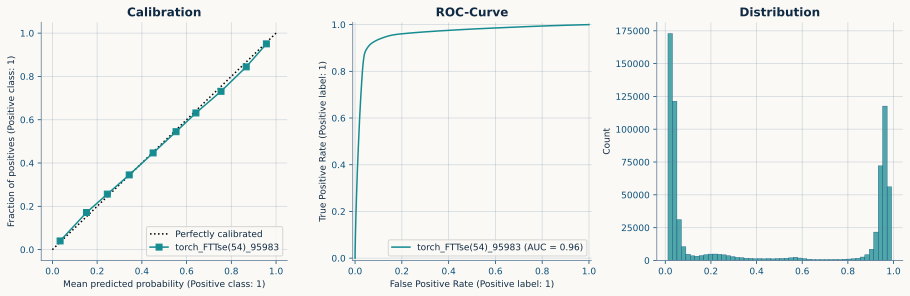

In [73]:
## -- Plot oof distributions --
_, axs = plt.subplots(1, 3, figsize=(12.5, 4))

CalibrationDisplay.from_predictions(y, oof_preds, n_bins=10, name=n, ax=axs[0])
axs[0].set_title(f"Calibration")

RocCurveDisplay.from_predictions(y, oof_preds, name=n, ax=axs[1])
axs[1].set_title(f"ROC-Curve")

sns.histplot(oof_preds, ax=axs[2], bins=50)
axs[2].set_title(f"Distribution")

# for ax in axs:
#     ax.legend(loc='lower right')

plt.tight_layout(pad=0.2)
plt.show()

In [74]:
# ## -- Feature Importances --
# top_n = 30

# imp_df = pd.Series(np.mean(feat_importances, axis=0), index=features_used).sort_values()[-top_n:]
# print(f"Total used features: {len(features_used)}\n")

# ax = imp_df.plot.barh(figsize=(12.5, len(imp_df)*0.3))
# ax.set_title(f"{n}: Avg. {FOLDS}-Fold Importances", loc='left')
# ax.grid(True)

# plt.tight_layout()
# plt.show()